In [23]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))


/kaggle/input/datasets/ayaansajidnalakath/tawos-cleaned/TAWOS.parquet


In [24]:

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/ayaansajidnalakath/tawos-cleaned/TAWOS.parquet"

df = pd.read_parquet(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head(10))


Dataset loaded successfully!
Shape: (458232, 19)


,Issue_ID,Issue_Key,Project_ID,Project_Name,Title,Description,Description_Text,Story_Point,Type,Priority,Status,Creation_Date,Estimation_Date,Resolution_Date,Last_Updated,Story_Point_Changed_After_Estimation,Description_Changed_After_Estimation,Title_Changed_After_Estimation,Sprint_ID
0,65,XD-3768,1,Spring XD,"""How do I make a job restartable in spring xd""","""The jobs that appear under Executions section...","""""""The jobs that appear under Executions secti...",1.0,Bug,Major,To Do,2017-07-10 13:41:25,2017-07-10 12:41:25,NaT,2017-07-10 13:41:25,0,0,0,NaN
1,66,XD-3767,1,Spring XD,"""admin config timezone command does not work""","""Working with Spring-XD version 1.3.2.RELEASE ...","""""""Working with Spring-XD version 1.3.2.RELEAS...",1.0,Bug,Trivial,To Do,2017-06-26 16:26:27,2017-06-26 15:26:27,NaT,2017-06-26 16:26:27,0,0,0,NaN
2,67,XD-3766,1,Spring XD,"""Module Upload command not pushing jar to all ...","""My project 7 node cluster and in that 2 node ...","""""""My project 7 node cluster and in that 2 nod...",10.0,Bug,Major,To Do,2017-05-19 22:28:43,2017-05-19 21:28:43,NaT,2017-05-19 22:28:43,0,0,0,NaN
3,68,XD-3765,1,Spring XD,"""Fix stream failover ""","""See https://github.com/spring-projects/spring...","""""""See https://github.com/spring-projects/spri...",8.0,Story,Minor,Done,2017-03-21 16:54:44,2017-03-21 16:54:44,2017-03-21 16:55:23,2017-03-22 18:27:01,0,0,1,NaN
4,69,XD-3764,1,Spring XD,"""SpringXD Job is still executing even after fo...","""I'm trying to run a Job on SpringXD and the j...","""""""I'm trying to run a Job on SpringXD and the...",5.0,Bug,Major,To Do,2017-03-06 20:01:41,2017-03-06 20:01:41,NaT,2017-03-06 20:01:41,0,0,0,NaN
5,70,XD-3763,1,Spring XD,"""Duplicate entries in table XD_JOB_REGISTRY""","""Hello, I have encountered following problem ...","""""""Hello, I have encountered following proble...",1.0,Bug,Major,To Do,2017-01-23 10:21:08,2017-01-23 10:21:08,NaT,2017-01-23 10:24:49,0,0,0,NaN
6,71,XD-3762,1,Spring XD,"""Spring XD Dynamic Module ClassLoader Issue""","""According to the documentation we can load ja...","""""""According to the documentation we can load ...",1.0,Bug,Critical,To Do,2016-11-07 09:10:20,2016-11-07 09:10:20,NaT,2016-11-07 09:12:02,0,0,0,NaN
7,72,XD-3761,1,Spring XD,"""java.util.concurrent.RejectedExecutionExcepti...","""Hi, We use spring config server 1.0.4-RELEA...","""""""Hi, We use spring config server 1.0.4-REL...",1.0,Bug,Major,To Do,2016-09-25 09:03:53,2016-09-25 08:03:53,NaT,2016-09-28 06:31:25,0,0,0,NaN
8,73,XD-3760,1,Spring XD,"""SpringXD authenication and authorization usin...","""Hi, I'm using LDAP to a Windows Active Direc...","""""""Hi, I'm using LDAP to a Windows Active Dir...",1.0,Improvement,Minor,To Do,2016-09-19 06:43:48,2016-09-19 05:43:48,NaT,2018-03-28 02:03:27,0,0,0,NaN
9,74,XD-3759,1,Spring XD,"""Composed job endpoint is missing from the def...","""More details in the support ticket: https://i...","""""""More details in the support ticket: https:/...",1.0,Bug,Minor,To Do,2016-07-19 21:56:06,2016-07-19 20:56:06,NaT,2016-12-23 14:48:09,0,0,0,NaN


In [25]:
print("=" * 60)
print("TAWOS DATASET OVERVIEW")
print("=" * 60)

print("Total records:", f"{len(df):,}")
print("Total columns:", len(df.columns))
print("Unique projects:", df["Project_Name"].nunique())
print("Unique issue IDs:", f"{df['Issue_ID'].nunique():,}")

# Column information
print("\n--- COLUMN TYPES ---")

display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Missing (%)": (df.isna().mean() * 100).round(2).values
}))

# Story point statistics
print("\n--- STORY POINT LABELS ---")

print("Labelled issues:", f"{df['Story_Point'].notna().sum():,}")
print("Unlabelled issues:", f"{df['Story_Point'].isna().sum():,}")
print("Unique story point values:", df["Story_Point"].nunique())

print("\nStory point statistics:")
display(df["Story_Point"].describe())

# Project-wise statistics
print("\n--- PROJECT-WISE DISTRIBUTION ---")

project_summary = (
    df.groupby("Project_Name")
    .agg(
        Total_Issues=("Issue_ID", "count"),
        Labelled_Issues=("Story_Point", "count"),
        Unique_Story_Points=("Story_Point", "nunique")
    )
    .sort_values("Total_Issues", ascending=False)
)

project_summary["Unlabelled_Issues"] = (
    project_summary["Total_Issues"]
    - project_summary["Labelled_Issues"]
)

display(project_summary)

# Existing duplicate checks
print("\n--- DATA INTEGRITY ---")

print("Duplicate issue IDs:", df["Issue_ID"].duplicated().sum())
print("Completely duplicated rows:", df.duplicated().sum())

# Sample labelled issues
print("\n--- SAMPLE LABELLED ISSUES ---")

display(
    df[df["Story_Point"].notna()][
        ["Issue_Key", "Project_Name", "Title",
         "Description_Text", "Story_Point"]
    ].head(10)
)

print("\nDataset inspection complete.")

TAWOS DATASET OVERVIEW
Total records: 458,232
Total columns: 19
Unique projects: 39
Unique issue IDs: 458,232

--- COLUMN TYPES ---


,Column,Data Type,Missing Values,Missing (%)
0,Issue_ID,int64,0,0.00
1,Issue_Key,object,0,0.00
2,Project_ID,int64,0,0.00
3,Project_Name,object,0,0.00
4,Title,object,0,0.00
5,Description,object,0,0.00
6,Description_Text,object,0,0.00
7,Story_Point,float64,392805,85.72
8,Type,object,0,0.00
9,Priority,object,0,0.00



--- STORY POINT LABELS ---
Labelled issues: 65,427
Unlabelled issues: 392,805
Unique story point values: 367

Story point statistics:


count    6.542700e+04
mean     4.135718e+02
std      1.044232e+05
min      0.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      5.000000e+00
max      2.671011e+07
Name: Story_Point, dtype: float64


--- PROJECT-WISE DISTRIBUTION ---


,Total_Issues,Labelled_Issues,Unique_Story_Points,Unlabelled_Issues
Project_Name,,,,
Moodle,66741,1594,27,65147
MongoDB Core Server,48663,784,12,47879
Atlassian Jira Server,44165,380,12,43785
Atlassian Confluence Server,42324,662,9,41662
Lsstcorp Data management,26506,20664,347,5842
Atlassian Jira Cloud,25669,361,9,25308
Atlassian Confluence Cloud,23409,352,10,23057
The Titanium SDK,22059,4665,37,17394
Atlassian Bamboo,14252,528,11,13724



--- DATA INTEGRITY ---
Duplicate issue IDs: 0
Completely duplicated rows: 0

--- SAMPLE LABELLED ISSUES ---


,Issue_Key,Project_Name,Title,Description_Text,Story_Point
0,XD-3768,Spring XD,"""How do I make a job restartable in spring xd""","""""""The jobs that appear under Executions secti...",1.0
1,XD-3767,Spring XD,"""admin config timezone command does not work""","""""""Working with Spring-XD version 1.3.2.RELEAS...",1.0
2,XD-3766,Spring XD,"""Module Upload command not pushing jar to all ...","""""""My project 7 node cluster and in that 2 nod...",10.0
3,XD-3765,Spring XD,"""Fix stream failover ""","""""""See https://github.com/spring-projects/spri...",8.0
4,XD-3764,Spring XD,"""SpringXD Job is still executing even after fo...","""""""I'm trying to run a Job on SpringXD and the...",5.0
5,XD-3763,Spring XD,"""Duplicate entries in table XD_JOB_REGISTRY""","""""""Hello, I have encountered following proble...",1.0
6,XD-3762,Spring XD,"""Spring XD Dynamic Module ClassLoader Issue""","""""""According to the documentation we can load ...",1.0
7,XD-3761,Spring XD,"""java.util.concurrent.RejectedExecutionExcepti...","""""""Hi, We use spring config server 1.0.4-REL...",1.0
8,XD-3760,Spring XD,"""SpringXD authenication and authorization usin...","""""""Hi, I'm using LDAP to a Windows Active Dir...",1.0
9,XD-3759,Spring XD,"""Composed job endpoint is missing from the def...","""""""More details in the support ticket: https:/...",1.0



Dataset inspection complete.


In [26]:
print("Story Point vs Estimation Date consistency")

print(pd.crosstab(
    df["Story_Point"].isna(),
    df["Estimation_Date"].isna(),
    rownames=["Story_Point missing"],
    colnames=["Estimation_Date missing"]
))

print("\nStory point values equal to zero:",
      (df["Story_Point"] == 0).sum())

print("\nUnresolved issues:",
      df["Resolution_Date"].isna().sum())

Story Point vs Estimation Date consistency
Estimation_Date missing  False   True 
Story_Point missing                   
False                    65427       0
True                         0  392805

Story point values equal to zero: 2416

Unresolved issues: 105600


In [27]:
# Keep only issues with known story-point labels
df_labelled = df[df["Story_Point"].notna()].copy()

df_labelled.reset_index(drop=True, inplace=True)

print("Original dataset:", df.shape)
print("Labelled dataset:", df_labelled.shape)

print("\nMissing Story Points:",
      df_labelled["Story_Point"].isna().sum())

df_labelled.to_parquet(
    "/kaggle/working/TAWOS_labelled.parquet",
    index=False
)

print("\nSaved TAWOS_labelled.parquet")

Original dataset: (458232, 19)
Labelled dataset: (65427, 19)

Missing Story Points: 0

Saved TAWOS_labelled.parquet


In [28]:
print("--- DUPLICATE ISSUE KEYS ---")

print(
    "Duplicate Issue_Key:",
    df_labelled["Issue_Key"].duplicated().sum()
)

print("\n--- TEXT QUALITY ---")

title_empty = (
    df_labelled["Title"].fillna("").str.strip().eq("")
)

desc_empty = (
    df_labelled["Description_Text"].fillna("").str.strip().eq("")
)

both_empty = title_empty & desc_empty

print("Empty titles:", title_empty.sum())
print("Empty descriptions:", desc_empty.sum())
print("Both title and description empty:", both_empty.sum())

print("\n--- DUPLICATE TEXT ---")

print(
    "Duplicate title + description:",
    df_labelled.duplicated(
        subset=["Title", "Description_Text"]
    ).sum()
)

print("\n--- STORY POINT QUALITY ---")

print("Negative Story Points:",
      (df_labelled["Story_Point"] < 0).sum())

print("\nStory Point percentiles:")

display(
    df_labelled["Story_Point"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    )
)

print("\nLargest Story Point values:")

display(df_labelled["Story_Point"].nlargest(20))

--- DUPLICATE ISSUE KEYS ---
Duplicate Issue_Key: 0

--- TEXT QUALITY ---
Empty titles: 0
Empty descriptions: 6942
Both title and description empty: 0

--- DUPLICATE TEXT ---
Duplicate title + description: 552

--- STORY POINT QUALITY ---
Negative Story Points: 0

Story Point percentiles:


count    6.542700e+04
mean     4.135718e+02
std      1.044232e+05
min      0.000000e+00
50%      3.000000e+00
90%      8.000000e+00
95%      1.400000e+01
99%      5.000000e+01
99.9%    1.375740e+02
max      2.671011e+07
Name: Story_Point, dtype: float64


Largest Story Point values:


3732     26710114.0
60643        6765.0
61802        3030.0
1159         2567.0
3775         1000.0
13774         688.0
14087         688.0
37388         300.0
61325         220.0
30995         218.0
61294         216.0
38134         210.0
39201         210.0
39773         204.0
29581         200.0
32688         200.0
33429         195.0
48026         195.0
33435         191.0
27790         190.0
Name: Story_Point, dtype: float64

In [29]:
# DATA CLEANING

df_cleaned = df_labelled.copy()

# Remove rows only when BOTH title and description are missing or empty
df_cleaned = df_cleaned[
    (df_cleaned["Title"].fillna("").str.strip() != "") |
    (df_cleaned["Description_Text"].fillna("").str.strip() != "")
].copy()

# Reset index
df_cleaned.reset_index(drop=True, inplace=True)

# Display cleaning results
print("Labelled dataset shape:", df_labelled.shape)
print("Cleaned dataset shape:", df_cleaned.shape)
print("Rows removed:", len(df_labelled) - len(df_cleaned))

print("\nRemaining missing values:")
print(df_cleaned[["Story_Point", "Title", "Description_Text"]].isna().sum())

print("\nRows with both title and description empty:",
      (
          (df_cleaned["Title"].fillna("").str.strip() == "") &
          (df_cleaned["Description_Text"].fillna("").str.strip() == "")
      ).sum())

display(df_cleaned.head())

Labelled dataset shape: (65427, 19)
Cleaned dataset shape: (65427, 19)
Rows removed: 0

Remaining missing values:
Story_Point         0
Title               0
Description_Text    0
dtype: int64

Rows with both title and description empty: 0


,Issue_ID,Issue_Key,Project_ID,Project_Name,Title,Description,Description_Text,Story_Point,Type,Priority,Status,Creation_Date,Estimation_Date,Resolution_Date,Last_Updated,Story_Point_Changed_After_Estimation,Description_Changed_After_Estimation,Title_Changed_After_Estimation,Sprint_ID
0,65,XD-3768,1,Spring XD,"""How do I make a job restartable in spring xd""","""The jobs that appear under Executions section...","""""""The jobs that appear under Executions secti...",1.0,Bug,Major,To Do,2017-07-10 13:41:25,2017-07-10 12:41:25,NaT,2017-07-10 13:41:25,0,0,0,NaN
1,66,XD-3767,1,Spring XD,"""admin config timezone command does not work""","""Working with Spring-XD version 1.3.2.RELEASE ...","""""""Working with Spring-XD version 1.3.2.RELEAS...",1.0,Bug,Trivial,To Do,2017-06-26 16:26:27,2017-06-26 15:26:27,NaT,2017-06-26 16:26:27,0,0,0,NaN
2,67,XD-3766,1,Spring XD,"""Module Upload command not pushing jar to all ...","""My project 7 node cluster and in that 2 node ...","""""""My project 7 node cluster and in that 2 nod...",10.0,Bug,Major,To Do,2017-05-19 22:28:43,2017-05-19 21:28:43,NaT,2017-05-19 22:28:43,0,0,0,NaN
3,68,XD-3765,1,Spring XD,"""Fix stream failover ""","""See https://github.com/spring-projects/spring...","""""""See https://github.com/spring-projects/spri...",8.0,Story,Minor,Done,2017-03-21 16:54:44,2017-03-21 16:54:44,2017-03-21 16:55:23,2017-03-22 18:27:01,0,0,1,NaN
4,69,XD-3764,1,Spring XD,"""SpringXD Job is still executing even after fo...","""I'm trying to run a Job on SpringXD and the j...","""""""I'm trying to run a Job on SpringXD and the...",5.0,Bug,Major,To Do,2017-03-06 20:01:41,2017-03-06 20:01:41,NaT,2017-03-06 20:01:41,0,0,0,NaN


In [30]:
# PROJECT-WISE STORY POINT STATISTICS

project_stats = (
    df_cleaned.groupby("Project_Name")["Story_Point"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .sort_values("Count", ascending=False)
)

display(project_stats.round(2))

print("\nOverall Story Point Statistics:")

display(
    df_cleaned["Story_Point"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]
    )
)

print("\nLargest Story Point values:")

display(
    df_cleaned.nlargest(20, "Story_Point")[
        ["Project_Name", "Issue_Key", "Title", "Story_Point"]
    ]
)

,Count,Mean,Median,Std,Min,Max
Project_Name,,,,,,
Lsstcorp Data management,20664,7.55,3.0,16.08,0.0,300.0
The MongoDB Engineering,5402,1.76,2.0,1.17,0.0,8.0
The Titanium SDK,4665,7.24,5.0,99.33,0.0,6765.0
Mule,4170,4.46,4.0,4.20,0.0,60.0
Spring XD,3705,4.33,3.0,42.34,0.0,2567.0
Appcelerator Studio,3406,5.48,5.0,4.24,0.0,144.0
Apache Mesos,3272,3.22,3.0,2.32,0.0,40.0
DotNetNuke Platform,2594,2.16,2.0,2.53,0.0,100.0
Sonatype Nexus,1845,1.78,1.0,2.07,0.0,40.0



Overall Story Point Statistics:


count    6.542700e+04
mean     4.135718e+02
std      1.044232e+05
min      0.000000e+00
50%      3.000000e+00
90%      8.000000e+00
95%      1.400000e+01
99%      5.000000e+01
99.9%    1.375740e+02
max      2.671011e+07
Name: Story_Point, dtype: float64


Largest Story Point values:


,Project_Name,Issue_Key,Title,Story_Point
3732,Spring DataCass,DATACASS-228,"""Simple CassandraRepository implementation is ...",26710114.0
60643,The Titanium SDK,TIMOB-18052,"""iOS: Support WatchKit""",6765.0
61802,Atlassian Jira Cloud,JRACLOUD-62509,"""Add information about Versions for JSON impor...",3030.0
1159,Spring XD,XD-2602,"""trying to import data from MS SQL tables to h...",2567.0
3775,Spring DataCass,DATACASS-185,"""Investigate support for datastax annotation m...",1000.0
13774,Atlassian Software Cloud,JSWCLOUD-10638,"""fjjjjjjjjjjjjjjjjjjjjjj""",688.0
14087,Atlassian Atlassian Software Server,JSWSERVER-10638,"""fjjjjjjjjjjjjjjjjjjjjjj""",688.0
37388,Lsstcorp Data management,DM-4651,"""Convert GWT code to pure JavaScript (X16)""",300.0
61325,The Titanium SDK,TIMOB-9051,"""BlackBerry: Implement UI.TextField - Part 2""",220.0
30995,Lsstcorp Data management,DM-12711,"""AP Pipeline Development in S18""",218.0


In [31]:
# INVESTIGATE EXTREME STORY POINT VALUES

extreme_issues = df_cleaned[
    df_cleaned["Story_Point"] >= 100
].sort_values(
    "Story_Point",
    ascending=False
)

print("Number of issues with Story Points >= 100:",
      len(extreme_issues))

for _, row in extreme_issues.head(15).iterrows():

    print("\n" + "=" * 70)
    print("Project:", row["Project_Name"])
    print("Issue Key:", row["Issue_Key"])
    print("Story Points:", row["Story_Point"])
    print("Title:", row["Title"])
    print("Description:",
          str(row["Description_Text"])[:500])

Number of issues with Story Points >= 100: 248

Project: Spring DataCass
Issue Key: DATACASS-228
Story Points: 26710114.0
Title: "Simple CassandraRepository implementation is not working"
Description: """POJO:  ---------   Repository : ----------------   spring-context-config.xml: ----------------------------------   *When i runs the  code,which throws an error message saying like :*  Here is the link: --------------------- http://stackoverflow.com/questions/26710114/cannot-resolve-reference-to-bean-cqltemplate-while-setting-bean-property-cass  Here is the stacktrace: ------------------------------   """

Project: The Titanium SDK 
Issue Key: TIMOB-18052
Story Points: 6765.0
Title: "iOS: Support WatchKit"
Description: """The iOS 8.2 beta includes support for WatchKit, implemented in a similar fashion to Share Extensions (TIMOB-17335)    https://developer.apple.com/watchkit/    We should provide support in the Titanium SDK for developing WatchKit-enabled applications."""

Project: Atlas

In [32]:
# INSPECT ALL EXTREME STORY POINT RECORDS

extreme_issues = df_cleaned[
    df_cleaned["Story_Point"] >= 100
].copy()

extreme_issues["Title_Length"] = (
    extreme_issues["Title"].fillna("").str.strip().str.len()
)

extreme_issues["Description_Length"] = (
    extreme_issues["Description_Text"].fillna("").str.strip().str.len()
)

print("Total extreme records:", len(extreme_issues))

print(
    extreme_issues[
        [
            "Project_Name",
            "Issue_Key",
            "Story_Point",
            "Title_Length",
            "Description_Length",
            "Title"
        ]
    ].sort_values(
        "Story_Point",
        ascending=False
    ).to_string(index=False)
)

Total extreme records: 248
                       Project_Name       Issue_Key  Story_Point  Title_Length  Description_Length                                                                                                                                          Title
                    Spring DataCass    DATACASS-228  26710114.00            58                 410                                                                                     "Simple CassandraRepository implementation is not working"
                  The Titanium SDK      TIMOB-18052      6765.00            23                 256                                                                                                                        "iOS: Support WatchKit"
               Atlassian Jira Cloud  JRACLOUD-62509      3030.00            50                 882                                                                                             "Add information about Versions for JSON importer"
     

In [33]:
# REMOVE IDENTIFIED SUSPICIOUS RECORDS & DUPLICATE ISSUE TEXTS

suspicious_issue_keys = [
    "DATACASS-228",
    "JSWSERVER-10638",
    "JSWCLOUD-10638"
]

df_model = df_cleaned[
    ~df_cleaned["Issue_Key"].isin(suspicious_issue_keys)
].copy()

print("Before cleaning:", df_cleaned.shape)
print("After removing suspicious records:", df_model.shape)

# Remove within-project duplicate (Title, Description_Text) pairs to prevent train/test text leakage
before_dedup = len(df_model)
df_model = df_model.drop_duplicates(
    subset=["Project_Name", "Title", "Description_Text"],
    keep="first"
).copy()

df_model.reset_index(drop=True, inplace=True)

print("Duplicate (Project_Name, Title, Description_Text) rows removed:", before_dedup - len(df_model))
print("Total rows removed:", len(df_cleaned) - len(df_model))

print("\nRemaining suspicious issue keys:")
print(
    df_model[
        df_model["Issue_Key"].isin(suspicious_issue_keys)
    ]["Issue_Key"].to_string(index=False)
)

# Save the final cleaned dataset after outlier & duplicate removal
CLEANED_PATH = "/kaggle/working/TAWOS_cleaned_labelled.parquet"

df_model.to_parquet(
    CLEANED_PATH,
    index=False
)

print("\nSaved final cleaned dataset:", CLEANED_PATH)
print("Final shape:", df_model.shape)

Before cleaning: (65427, 19)
After removing suspicious records: (65424, 19)
Duplicate (Project_Name, Title, Description_Text) rows removed: 354
Total rows removed: 357

Remaining suspicious issue keys:
Series([], )

Saved final cleaned dataset: /kaggle/working/TAWOS_cleaned_labelled.parquet
Final shape: (65070, 19)


In [34]:
projects = sorted(df_model["Project_Name"].unique())

print(f"Projects with labelled issues: {len(projects)}\n")

for i, project in enumerate(projects, start=1):

    count = (
        df_model["Project_Name"] == project
    ).sum()

    print(f"{i:02d}. {project}: {count:,} labelled issues")

Projects with labelled issues: 39

01. Alloy Framework: 315 labelled issues
02. Apache MXNet: 208 labelled issues
03. Apache Mesos: 3,271 labelled issues
04. Apache Usergrid: 486 labelled issues
05. Appcelerator Daemon: 242 labelled issues
06. Appcelerator Studio: 3,402 labelled issues
07. Aptana Studio: 890 labelled issues
08. Atlassian Atlassian Software Server: 349 labelled issues
09. Atlassian Bamboo : 526 labelled issues
10. Atlassian Clover: 387 labelled issues
11. Atlassian Confluence Cloud: 352 labelled issues
12. Atlassian Confluence Server: 662 labelled issues
13. Atlassian Crowd: 214 labelled issues
14. Atlassian FishEye: 239 labelled issues
15. Atlassian Jira Cloud: 361 labelled issues
16. Atlassian Jira Server: 380 labelled issues
17. Atlassian Software Cloud: 317 labelled issues
18. Command-Line Interface: 374 labelled issues
19. DotNetNuke Platform: 2,593 labelled issues
20. Hyperledger Blockchain Explorer: 373 labelled issues
21. Hyperledger Fabric: 634 labelled issues


In [35]:
project_dfs = {}

for project_name in projects:

    project_df = df_model[
        df_model["Project_Name"] == project_name
    ].copy()

    project_df.reset_index(drop=True, inplace=True)

    project_dfs[project_name] = project_df

print(f"Created {len(project_dfs)} project DataFrames\n")

for name, project_df in project_dfs.items():
    print(f"{name}: {len(project_df)} rows")

Created 39 project DataFrames

Alloy Framework: 315 rows
Apache MXNet: 208 rows
Apache Mesos: 3271 rows
Apache Usergrid: 486 rows
Appcelerator Daemon: 242 rows
Appcelerator Studio: 3402 rows
Aptana Studio: 890 rows
Atlassian Atlassian Software Server: 349 rows
Atlassian Bamboo : 526 rows
Atlassian Clover: 387 rows
Atlassian Confluence Cloud: 352 rows
Atlassian Confluence Server: 662 rows
Atlassian Crowd: 214 rows
Atlassian FishEye: 239 rows
Atlassian Jira Cloud: 361 rows
Atlassian Jira Server: 380 rows
Atlassian Software Cloud: 317 rows
Command-Line Interface: 374 rows
DotNetNuke Platform: 2593 rows
Hyperledger Blockchain Explorer: 373 rows
Hyperledger Fabric: 634 rows
Hyperledger Indy Node: 681 rows
Hyperledger Indy SDK: 720 rows
Hyperledger Sawtooth: 957 rows
Lsstcorp Data management: 20357 rows
Lyrasis Dura Cloud: 666 rows
MongoDB Compass : 498 rows
MongoDB Core Server: 784 rows
Moodle: 1593 rows
Mule: 4166 rows
Mule APIkit: 473 rows
Sonatype Nexus: 1844 rows
Spring DataCass: 241 ro

In [36]:
for project_name, pdf in project_dfs.items():

    pdf["Issue_Text"] = (
        "Title: "
        + pdf["Title"].fillna("").astype(str)
        + "\nDescription: "
        + pdf["Description_Text"].fillna("").astype(str)
    )

print("Issue_Text created for all projects.")

# Inspect an example
display(
    project_dfs["Mule"][
        ["Title", "Description_Text", "Issue_Text", "Story_Point"]
    ].head()
)

Issue_Text created for all projects.


,Title,Description_Text,Issue_Text,Story_Point
0,"""LazyMuleArtifactContext ignores custom Global...","""""""LazyMuleArtifactContext ignore custom Globa...","Title: ""LazyMuleArtifactContext ignores custom...",0.0
1,"""Parameter that are included as child elements...","""""""Parameters that are declared as child eleme...","Title: ""Parameter that are included as child e...",4.0
2,"""Automate Update of License year, and update i...","""""""Update License year to 2019""""""","Title: ""Automate Update of License year, and u...",4.0
3,"""Allow to enable logs on tooling applications ...","""""""Application deployed for Tooling have the l...","Title: ""Allow to enable logs on tooling applic...",0.0
4,"""Upgrade Mockito in Integration tests""","""""""Upgrade Mockito to the latest version that ...","Title: ""Upgrade Mockito in Integration tests""\...",8.0


In [37]:
from sklearn.model_selection import train_test_split

project_train_dfs = {}
project_test_dfs = {}

for project_name, pdf in project_dfs.items():

    train_df, test_df = train_test_split(
        pdf,
        test_size=0.20,
        random_state=42,
        shuffle=True
    )

    project_train_dfs[project_name] = train_df.reset_index(drop=True)
    project_test_dfs[project_name] = test_df.reset_index(drop=True)

print("Project-wise splitting completed!\n")

for name in projects:

    print(
        f"{name}: "
        f"Development = {len(project_train_dfs[name])}, "
        f"Test = {len(project_test_dfs[name])}"
    )

Project-wise splitting completed!

Alloy Framework: Development = 252, Test = 63
Apache MXNet: Development = 166, Test = 42
Apache Mesos: Development = 2616, Test = 655
Apache Usergrid: Development = 388, Test = 98
Appcelerator Daemon: Development = 193, Test = 49
Appcelerator Studio: Development = 2721, Test = 681
Aptana Studio: Development = 712, Test = 178
Atlassian Atlassian Software Server: Development = 279, Test = 70
Atlassian Bamboo : Development = 420, Test = 106
Atlassian Clover: Development = 309, Test = 78
Atlassian Confluence Cloud: Development = 281, Test = 71
Atlassian Confluence Server: Development = 529, Test = 133
Atlassian Crowd: Development = 171, Test = 43
Atlassian FishEye: Development = 191, Test = 48
Atlassian Jira Cloud: Development = 288, Test = 73
Atlassian Jira Server: Development = 304, Test = 76
Atlassian Software Cloud: Development = 253, Test = 64
Command-Line Interface: Development = 299, Test = 75
DotNetNuke Platform: Development = 2074, Test = 519
Hyp

In [38]:
# Verify that every project has an 80:20 split
for name in projects:

    original_count = len(project_dfs[name])
    train_count = len(project_train_dfs[name])
    test_count = len(project_test_dfs[name])

    assert train_count + test_count == original_count

    assert set(project_train_dfs[name]["Issue_ID"]).isdisjoint(
        set(project_test_dfs[name]["Issue_ID"])
    )

    print(
        f"{name}: "
        f"{train_count / original_count:.1%} development, "
        f"{test_count / original_count:.1%} test"
    )

print("\nAll split checks passed!")

Alloy Framework: 80.0% development, 20.0% test
Apache MXNet: 79.8% development, 20.2% test
Apache Mesos: 80.0% development, 20.0% test
Apache Usergrid: 79.8% development, 20.2% test
Appcelerator Daemon: 79.8% development, 20.2% test
Appcelerator Studio: 80.0% development, 20.0% test
Aptana Studio: 80.0% development, 20.0% test
Atlassian Atlassian Software Server: 79.9% development, 20.1% test
Atlassian Bamboo : 79.8% development, 20.2% test
Atlassian Clover: 79.8% development, 20.2% test
Atlassian Confluence Cloud: 79.8% development, 20.2% test
Atlassian Confluence Server: 79.9% development, 20.1% test
Atlassian Crowd: 79.9% development, 20.1% test
Atlassian FishEye: 79.9% development, 20.1% test
Atlassian Jira Cloud: 79.8% development, 20.2% test
Atlassian Jira Server: 80.0% development, 20.0% test
Atlassian Software Cloud: 79.8% development, 20.2% test
Command-Line Interface: 79.9% development, 20.1% test
DotNetNuke Platform: 80.0% development, 20.0% test
Hyperledger Blockchain Explo

In [39]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, median_absolute_error

# Reproducibility configuration
CONFIG = {
    "seed": 42,
    "model_name": "bert-base-uncased",
    "max_length": 128,
    "embed_batch_size": 64,
    "train_batch_size": 32,
    "epochs": 20,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "patience": 4,
    "n_folds": 5,
    "cnn_channels": [768, 256, 128, 64],
    "kernel_size": 3,
    "dropout": 0.3
}

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"])
bert_model = AutoModel.from_pretrained(CONFIG["model_name"]).to(device)
bert_model.eval()

print(f"Loaded {CONFIG['model_name']} successfully!")

Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded bert-base-uncased successfully!


In [40]:
@torch.no_grad()
def extract_bert_token_embeddings(texts, tokenizer, model, device, max_length=128, batch_size=64):
    """
    Extracts contextual token-level representations (last_hidden_state)
    of shape (num_samples, max_length, 768) in float16 to save memory.
    """
    all_embeddings = []
    texts_list = list(texts)

    for i in range(0, len(texts_list), batch_size):
        batch_texts = texts_list[i : i + batch_size]
        encoded = tokenizer(
            batch_texts,
            padding="max_length",
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )
        input_ids = encoded["input_ids"].to(device)
        attention_mask = encoded["attention_mask"].to(device)
        with torch.amp.autocast("cuda"):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        # Shape: (batch_size, max_length, 768)
        token_embeddings = outputs.last_hidden_state.half().cpu().numpy()
        all_embeddings.append(token_embeddings)

    return np.concatenate(all_embeddings, axis=0)

# Quick shape verification on one small project
sample_emb = extract_bert_token_embeddings(
    project_train_dfs["Appcelerator Daemon"]["Issue_Text"].head(4),
    tokenizer,
    bert_model,
    device,
    max_length=CONFIG["max_length"]
)
print("Verified single-batch token embedding shape:", sample_emb.shape)

Verified single-batch token embedding shape: (4, 128, 768)


In [41]:
class StoryPointCNN1D(nn.Module):
    def __init__(self, embed_dim=768, dropout=0.3):
        super().__init__()
        # 3-layer 1D Convolutional Network operating along token sequence
        self.conv_block1 = nn.Sequential(
            nn.Conv1d(in_channels=embed_dim, out_channels=256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv1d(in_channels=256, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.conv_block3 = nn.Sequential(
            nn.Conv1d(in_channels=128, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveMaxPool1d(output_size=1)
        )
        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # Input x shape: (batch_size, seq_len, embed_dim)
        # Permute for Conv1d: (batch_size, embed_dim, seq_len)
        x = x.permute(0, 2, 1)
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        out = self.regressor(x).squeeze(-1)
        return out


def train_and_evaluate_cnn(X_train, y_train, X_val=None, y_val=None, config=CONFIG):
    """
    Trains StoryPointCNN1D using L1Loss (MAE).
    If validation data is provided, applies early stopping based on validation MAE.
    """
    set_seed(config["seed"])
    model = StoryPointCNN1D(embed_dim=768, dropout=config["dropout"]).to(device)
    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"]
    )

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=config["train_batch_size"],
        shuffle=True
    )

    best_val_mae = float("inf")
    best_weights = None
    epochs_no_improve = 0

    for epoch in range(config["epochs"]):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            preds = model(batch_x)
            loss = criterion(preds, batch_y)
            loss.backward()
            optimizer.step()

        if X_val is not None and y_val is not None:
            val_preds = predict_cnn(model, X_val, config["train_batch_size"])
            val_mae = mean_absolute_error(y_val, val_preds)

            if val_mae < best_val_mae:
                best_val_mae = val_mae
                best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= config["patience"]:
                    break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    return model


@torch.no_grad()
def predict_cnn(model, X, batch_size=64):
    model.eval()
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    preds = []
    for (batch_x,) in loader:
        batch_x = batch_x.to(device)
        batch_preds = model(batch_x).cpu().numpy()
        preds.append(batch_preds)
    # Clip negative predictions since story points >= 0
    return np.clip(np.concatenate(preds, axis=0), a_min=0.0, a_max=None)

In [42]:
import gc

kf = KFold(n_splits=CONFIG["n_folds"], shuffle=True, random_state=CONFIG["seed"])

cv_fold_records = []
summary_records = []

for idx, project_name in enumerate(projects, start=1):
    train_df = project_train_dfs[project_name]
    test_df = project_test_dfs[project_name]

    y_dev = train_df["Story_Point"].values.astype(np.float32)
    y_test = test_df["Story_Point"].values.astype(np.float32)

    # 1. Extract BERT token embeddings for dev and test splits
    X_dev = extract_bert_token_embeddings(
        train_df["Issue_Text"], tokenizer, bert_model, device,
        max_length=CONFIG["max_length"], batch_size=CONFIG["embed_batch_size"]
    )
    X_test = extract_bert_token_embeddings(
        test_df["Issue_Text"], tokenizer, bert_model, device,
        max_length=CONFIG["max_length"], batch_size=CONFIG["embed_batch_size"]
    )

    # 2. Five-Fold Cross-Validation on 80% Development Set
    fold_maes = []
    fold_mdaes = []

    for fold, (tr_idx, val_idx) in enumerate(kf.split(X_dev), start=1):
        X_tr, y_tr = X_dev[tr_idx], y_dev[tr_idx]
        X_va, y_va = X_dev[val_idx], y_dev[val_idx]

        fold_model = train_and_evaluate_cnn(X_tr, y_tr, X_va, y_va, CONFIG)
        val_preds = predict_cnn(fold_model, X_va, CONFIG["embed_batch_size"])

        f_mae = mean_absolute_error(y_va, val_preds)
        f_mdae = median_absolute_error(y_va, val_preds)

        fold_maes.append(f_mae)
        fold_mdaes.append(f_mdae)

        cv_fold_records.append({
            "Project_Name": project_name,
            "Fold": fold,
            "Val_MAE": f_mae,
            "Val_MdAE": f_mdae
        })

        del fold_model
        torch.cuda.empty_cache()

    # 3. Train on Full 80% Development Set & Evaluate on Held-Out 20% Test Set
    final_model = train_and_evaluate_cnn(X_dev, y_dev, X_val=None, y_val=None, config=CONFIG)
    test_preds = predict_cnn(final_model, X_test, CONFIG["embed_batch_size"])

    test_mae = mean_absolute_error(y_test, test_preds)
    test_mdae = median_absolute_error(y_test, test_preds)

    summary_records.append({
        "Project_Name": project_name,
        "Dev_Count": len(train_df),
        "Test_Count": len(test_df),
        "CV_MAE_Mean": np.mean(fold_maes),
        "CV_MAE_Std": np.std(fold_maes),
        "CV_MdAE_Mean": np.mean(fold_mdaes),
        "CV_MdAE_Std": np.std(fold_mdaes),
        "Test_MAE": test_mae,
        "Test_MdAE": test_mdae
    })

    print(
        f"[{idx:02d}/{len(projects)}] {project_name:<35} | "
        f"5-Fold CV MAE: {np.mean(fold_maes):.3f} ± {np.std(fold_maes):.3f} | "
        f"5-Fold CV MdAE: {np.mean(fold_mdaes):.3f} ± {np.std(fold_mdaes):.3f} | "
        f"Test MAE: {test_mae:.3f} | Test MdAE: {test_mdae:.3f}"
    )

    # Free RAM/VRAM before next project
    del X_dev, X_test, final_model
    gc.collect()
    torch.cuda.empty_cache()

[01/39] Alloy Framework                     | 5-Fold CV MAE: 1.829 ± 0.123 | 5-Fold CV MdAE: 1.222 ± 0.255 | Test MAE: 1.880 | Test MdAE: 1.466
[02/39] Apache MXNet                        | 5-Fold CV MAE: 4.004 ± 2.573 | 5-Fold CV MdAE: 1.630 ± 0.299 | Test MAE: 4.137 | Test MdAE: 1.241
[03/39] Apache Mesos                        | 5-Fold CV MAE: 1.397 ± 0.061 | 5-Fold CV MdAE: 0.927 ± 0.041 | Test MAE: 1.499 | Test MdAE: 1.106
[04/39] Apache Usergrid                     | 5-Fold CV MAE: 0.957 ± 0.169 | 5-Fold CV MdAE: 0.531 ± 0.193 | Test MAE: 0.920 | Test MdAE: 0.659
[05/39] Appcelerator Daemon                 | 5-Fold CV MAE: 5.831 ± 1.935 | 5-Fold CV MdAE: 2.432 ± 0.596 | Test MAE: 4.661 | Test MdAE: 3.114
[06/39] Appcelerator Studio                 | 5-Fold CV MAE: 2.235 ± 0.092 | 5-Fold CV MdAE: 1.625 ± 0.059 | Test MAE: 2.417 | Test MdAE: 1.658
[07/39] Aptana Studio                       | 5-Fold CV MAE: 4.548 ± 0.614 | 5-Fold CV MdAE: 2.664 ± 0.204 | Test MAE: 5.048 | Test MdAE

In [43]:
import json

cv_folds_df = pd.DataFrame(cv_fold_records)
results_summary_df = pd.DataFrame(summary_records)

# Save CSVs and config for GitHub repository & report
cv_folds_df.to_csv("/kaggle/working/ps1_bert_cnn_5fold_details.csv", index=False)
results_summary_df.to_csv("/kaggle/working/ps1_bert_cnn_summary_results.csv", index=False)

with open("/kaggle/working/ps1_experiment_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

print("=== OVERALL ACROSS ALL 39 PROJECTS ===")
overall_table = pd.DataFrame({
    "Metric": [
        "5-Fold Validation MAE (Mean across projects)",
        "5-Fold Validation MdAE (Mean across projects)",
        "Held-Out Test MAE (Mean across projects)",
        "Held-Out Test MdAE (Mean across projects)",
        "Held-Out Test MAE (Median across projects)",
        "Held-Out Test MdAE (Median across projects)"
    ],
    "Value": [
        results_summary_df["CV_MAE_Mean"].mean(),
        results_summary_df["CV_MdAE_Mean"].mean(),
        results_summary_df["Test_MAE"].mean(),
        results_summary_df["Test_MdAE"].mean(),
        results_summary_df["Test_MAE"].median(),
        results_summary_df["Test_MdAE"].median()
    ]
})
display(overall_table.round(4))

print("\n=== PROJECT-WISE 5-FOLD CV & HELD-OUT TEST RESULTS ===")
display(results_summary_df.round(4))

=== OVERALL ACROSS ALL 39 PROJECTS ===


,Metric,Value
0,5-Fold Validation MAE (Mean across projects),2.2537
1,5-Fold Validation MdAE (Mean across projects),1.1362
2,Held-Out Test MAE (Mean across projects),3.2194
3,Held-Out Test MdAE (Mean across projects),1.2320
4,Held-Out Test MAE (Median across projects),1.6789
5,Held-Out Test MdAE (Median across projects),1.1064



=== PROJECT-WISE 5-FOLD CV & HELD-OUT TEST RESULTS ===


,Project_Name,Dev_Count,Test_Count,CV_MAE_Mean,CV_MAE_Std,CV_MdAE_Mean,CV_MdAE_Std,Test_MAE,Test_MdAE
0,Alloy Framework,252,63,1.8292,0.1234,1.2225,0.2546,1.8802,1.4659
1,Apache MXNet,166,42,4.0036,2.5727,1.6300,0.2987,4.1371,1.2407
2,Apache Mesos,2616,655,1.3971,0.0606,0.9267,0.0407,1.4994,1.1064
3,Apache Usergrid,388,98,0.9570,0.1693,0.5314,0.1932,0.9205,0.6592
4,Appcelerator Daemon,193,49,5.8310,1.9349,2.4317,0.5959,4.6611,3.1135
5,Appcelerator Studio,2721,681,2.2354,0.0916,1.6253,0.0588,2.4172,1.6585
6,Aptana Studio,712,178,4.5480,0.6137,2.6640,0.2041,5.0479,3.2280
7,Atlassian Atlassian Software Server,279,70,1.9985,0.3933,1.4426,0.3083,2.0613,1.2810
8,Atlassian Bamboo,420,106,1.1086,0.1394,0.7228,0.0913,1.4498,0.9114
9,Atlassian Clover,309,78,3.7961,0.4545,1.2021,0.1568,3.0296,1.6734


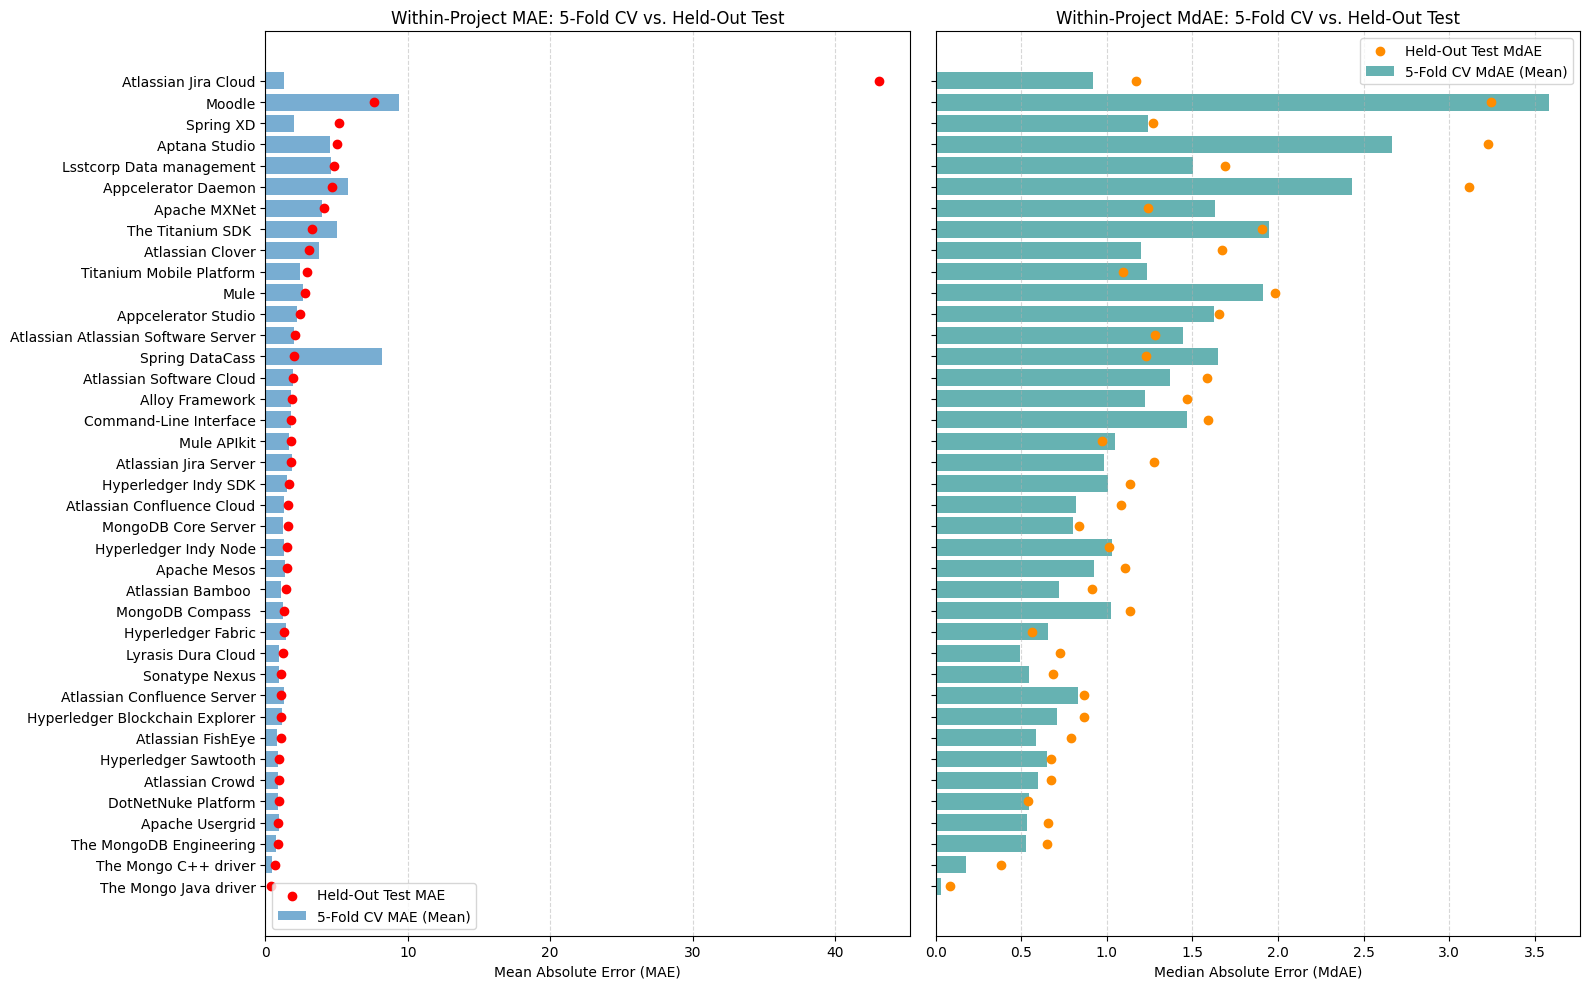

In [44]:
import matplotlib.pyplot as plt

sorted_res = results_summary_df.sort_values("Test_MAE", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)

# Plot 1: MAE (5-Fold CV vs Held-Out Test)
axes[0].barh(sorted_res["Project_Name"], sorted_res["CV_MAE_Mean"], alpha=0.6, label="5-Fold CV MAE (Mean)")
axes[0].scatter(sorted_res["Test_MAE"], sorted_res["Project_Name"], color="red", zorder=3, label="Held-Out Test MAE")
axes[0].set_xlabel("Mean Absolute Error (MAE)")
axes[0].set_title("Within-Project MAE: 5-Fold CV vs. Held-Out Test")
axes[0].legend()
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Plot 2: MdAE (5-Fold CV vs Held-Out Test)
axes[1].barh(sorted_res["Project_Name"], sorted_res["CV_MdAE_Mean"], alpha=0.6, color="teal", label="5-Fold CV MdAE (Mean)")
axes[1].scatter(sorted_res["Test_MdAE"], sorted_res["Project_Name"], color="darkorange", zorder=3, label="Held-Out Test MdAE")
axes[1].set_xlabel("Median Absolute Error (MdAE)")
axes[1].set_title("Within-Project MdAE: 5-Fold CV vs. Held-Out Test")
axes[1].legend()
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("/kaggle/working/ps1_bert_cnn_results_plot.png", dpi=300, bbox_inches="tight")
plt.show()